In [1]:
# ============================================================
# STEP 0: LOAD FROM SAVED CSVs IF AVAILABLE
# ============================================================
# If processed CSVs already exist, load them directly and skip
# the heavy processing (spatial joins, file parsing etc.)
# To force reprocessing from raw files, set FORCE_REPROCESS = True
# ============================================================
import sys
import os
import pandas as pd

FORCE_REPROCESS = False
# ── Paths ─────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE = "./Data"
OUTPUT_DIR     = f"{BASE}/../Processed Data"
baseline_path = f"{OUTPUT_DIR}/master_baseline.csv"
enhanced_path = f"{OUTPUT_DIR}/master_enhanced.csv"
full_path      = f"{OUTPUT_DIR}/master_full.csv"

all_exist = all(os.path.exists(p) for p in
                [baseline_path, enhanced_path, full_path])

if all_exist and not FORCE_REPROCESS:
    print("\n" + "=" * 65)
    print("STEP 0: Loading from saved CSVs")
    print("        (set FORCE_REPROCESS=True to rerun from raw files)")
    print("=" * 65)
    baseline_df = pd.read_csv(baseline_path)
    enhanced_df = pd.read_csv(enhanced_path)
    master_full = pd.read_csv(full_path)
    print(f"   master_baseline.csv  \u2192  {baseline_df.shape}")
    print(f"   master_enhanced.csv  \u2192  {enhanced_df.shape}")
    print(f"   master_full.csv      \u2192  {master_full.shape}")
    print(f"\nTrain: {(baseline_df['Split']=='train').sum()} rows  "
          f"| Test: {(baseline_df['Split']=='test').sum()} rows")
    print(f"Counties: {baseline_df['County'].nunique()}  "
          f"| Years: {sorted(baseline_df['Cal_Year'].unique())}")
    print("\n Ready for modeling — skipping preprocessing steps 1-10")

else:
    if FORCE_REPROCESS:
        print("\nSTEP 0: FORCE_REPROCESS=True — rerunning full pipeline")
    else:
        print("\nSTEP 0: Processed CSVs not found — running full pipeline")
    print("        (this will take 3-5 minutes due to spatial joins)\n")



STEP 0: Loading from saved CSVs
        (set FORCE_REPROCESS=True to rerun from raw files)
   master_baseline.csv  →  (348, 12)
   master_enhanced.csv  →  (348, 26)
   master_full.csv      →  (348, 33)

Train: 232 rows  | Test: 116 rows
Counties: 58  | Years: [np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

 Ready for modeling — skipping preprocessing steps 1-10


In [2]:
# ============================================================
# BASELINE MODELING — Insurance-Only Feature Set
# Models: GLM (Tweedie), Random Forest, XGBoost
# Evaluation: MAE, RMSE, R², per-county error analysis
# Data: master_baseline.csv (from preprocessing_pipeline.py)
#       Insurance source: Residential-Property-Coverage-Amounts-
#                         Wildfire-Risk-and-Losses.csv
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import FuncFormatter
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
import xgboost as xgb

# ── Paths ─────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE       = "./Data"
OUTPUT_DIR = f"{BASE}/../Processed Data"
PLOT_DIR   = f"{BASE}/../Plots"
import os; os.makedirs(PLOT_DIR, exist_ok=True)

# ── Load data ─────────────────────────────────────────────────
print("=" * 65)
print("BASELINE MODELS — Insurance-Only Feature Set")
print("=" * 65)

baseline_df = pd.read_csv(f"{OUTPUT_DIR}/master_baseline.csv")
print(f"Loaded: {baseline_df.shape}")

# ── Train/test split (before encoding to prevent leakage) ────
TARGET = "Total_Wildfire_Loss"
train = baseline_df[baseline_df["Split"] == "train"].copy()
test  = baseline_df[baseline_df["Split"] == "test"].copy()

# ── County Encoding: Target Encoding ─────────────────────────
# Replace county name with its mean loss from TRAINING DATA ONLY
# Superior to LabelEncoder (arbitrary integers) and One-Hot (57 cols)
# Works correctly for GLM, RF, and XGBoost equally
# CRITICAL: fit on train only — never on test (prevents data leakage)
county_mean_loss = (train.groupby("County")[TARGET]
                    .mean()
                    .rename("County_encoded"))

train["County_encoded"] = train["County"].map(county_mean_loss)
test["County_encoded"]  = test["County"].map(county_mean_loss)

# Safety net — fill unseen counties with training mean
global_train_mean = train["County_encoded"].mean()
test["County_encoded"] = test["County_encoded"].fillna(global_train_mean)

print(f"Target encoding — county mean loss (training data only):")
print(f"  Highest risk: {county_mean_loss.nlargest(3).index.tolist()}")
print(f"  Lowest risk:  {county_mean_loss.nsmallest(3).index.tolist()}")
print(f"  Range: ${county_mean_loss.min():,.0f} — ${county_mean_loss.max():,.0f}")

# ── Feature set (same for all models) ────────────────────────
FEATURES = [
    "County_encoded",   # target-encoded: mean loss from training
    "Cal_Year",
    "Earned_Exp",
    "Earned_Prem",
    "Avg_Cov_A",
    "Avg_Cov_C",
    "Log_Exposure",
    "Pure_Premium",
    "Loss_Ratio",
]
FEATURES_TREE = FEATURES  # alias for clarity
FEATURES_GLM  = FEATURES  # same features, all models

X_train     = train[FEATURES].astype(float)
X_test      = test[FEATURES].astype(float)
X_train_glm = X_train.copy()
X_test_glm  = X_test.copy()
y_train     = train[TARGET]
y_test      = test[TARGET]

print(f"\nTrain: {len(train)} rows | Test: {len(test)} rows")
print(f"Features ({len(FEATURES)}): {FEATURES}")

# ── Helper functions ──────────────────────────────────────────
def evaluate(y_true, y_pred, model_name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"\n  {model_name}")
    print(f"    MAE:  ${mae:>15,.0f}")
    print(f"    RMSE: ${rmse:>15,.0f}")
    print(f"    R²:    {r2:>15.4f}")
    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2": r2}

def county_errors(test_df, pred_col):
    """Per-county mean absolute error."""
    df = test_df.copy()
    df["abs_err"] = (df[pred_col] - df[TARGET]).abs()
    return (df.groupby("County")["abs_err"]
              .mean().reset_index()
              .rename(columns={"abs_err": "MAE"}))

BASELINE MODELS — Insurance-Only Feature Set
Loaded: (348, 12)
Target encoding — county mean loss (training data only):
  Highest risk: ['Butte', 'Los Angeles', 'Shasta']
  Lowest risk:  ['Sierra', 'Modoc', 'Colusa']
  Range: $95,461 — $1,359,072,890

Train: 232 rows | Test: 116 rows
Features (9): ['County_encoded', 'Cal_Year', 'Earned_Exp', 'Earned_Prem', 'Avg_Cov_A', 'Avg_Cov_C', 'Log_Exposure', 'Pure_Premium', 'Loss_Ratio']


In [3]:
# ============================================================
# MODEL 1: NAIVE BASELINE (global training mean)
# ============================================================
print("\n" + "=" * 65)
print("MODEL 1: Naive Baseline (global training mean)")
print("=" * 65)
# Simplest possible model — predict the same value for every
# county-year regardless of location or year
# This is the true lower bound all models must beat

global_mean = y_train.mean()
test["naive_pred"] = global_mean
print(f"  Global training mean: ${global_mean:,.0f}")

naive_metrics = evaluate(y_test, test["naive_pred"], "Naive Baseline")


MODEL 1: Naive Baseline (global training mean)
  Global training mean: $71,219,674

  Naive Baseline
    MAE:  $     56,930,276
    RMSE: $     66,816,549
    R²:            -0.6808


In [4]:
# ============================================================
# MODEL 2: GLM (Tweedie with log link)
# ============================================================
print("\n" + "=" * 65)
print("MODEL 2: GLM — Tweedie (p=1.5) with log link")
print("=" * 65)
# Tweedie compound Poisson-Gamma (p=1.5) is the actuarial
# standard for insurance loss modeling:
#   - Handles zero losses natively (no clipping needed)
#   - p=1.5 sits between Poisson (p=1) and Gamma (p=2)
#   - Models both P(loss=0) and E(loss|loss>0) simultaneously
# Only 2 zero-loss rows (0.6%) but Tweedie is more theoretically
# justified than Gamma + clip(lower=1) hack

X_train_glm_const = sm.add_constant(X_train_glm)
X_test_glm_const  = sm.add_constant(X_test_glm)
X_test_glm_const  = X_test_glm_const.reindex(
    columns=X_train_glm_const.columns, fill_value=0)

glm_model = sm.GLM(
    y_train,
    X_train_glm_const,
    family=sm.families.Tweedie(
        var_power=1.5,
        link=sm.families.links.Log()
    )
).fit()

print(glm_model.summary())

glm_pred         = glm_model.predict(X_test_glm_const)
test["glm_pred"] = glm_pred.values
glm_metrics      = evaluate(y_test, test["glm_pred"],
                             "GLM (Tweedie p=1.5)")


MODEL 2: GLM — Tweedie (p=1.5) with log link
                  Generalized Linear Model Regression Results                  
Dep. Variable:     Total_Wildfire_Loss   No. Observations:                  232
Model:                             GLM   Df Residuals:                      222
Model Family:                  Tweedie   Df Model:                            9
Link Function:                     Log   Scale:                          14871.
Method:                           IRLS   Log-Likelihood:                -4386.7
Date:                 Wed, 11 Mar 2026   Deviance:                   1.2993e+06
Time:                         08:03:03   Pearson chi2:                 3.30e+06
No. Iterations:                     21   Pseudo R-squ. (CS):             0.7611
Covariance Type:             nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------

In [5]:
# ============================================================
# MODEL 3: RANDOM FOREST
# ============================================================
print("\n" + "=" * 65)
print("MODEL 3: Random Forest")
print("=" * 65)

rf_model = RandomForestRegressor(
    n_estimators=200,     # sufficient for 232 training rows
    max_depth=None,       # unlimited depth — best from grid search
    min_samples_leaf=2,   # optimal from grid search (MAE $12.4M)
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
test["rf_pred"] = rf_model.predict(X_test)
rf_metrics      = evaluate(y_test, test["rf_pred"], "Random Forest")

# Feature importance
rf_importance = pd.DataFrame({
    "Feature":    FEATURES_TREE,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)
print(f"\n  Feature importance:")
print(rf_importance.to_string(index=False))


MODEL 3: Random Forest

  Random Forest
    MAE:  $     12,395,315
    RMSE: $     44,467,330
    R²:             0.2556

  Feature importance:
       Feature  Importance
    Loss_Ratio    0.373080
  Pure_Premium    0.298136
County_encoded    0.112306
   Earned_Prem    0.072775
    Earned_Exp    0.064269
  Log_Exposure    0.053304
      Cal_Year    0.015766
     Avg_Cov_A    0.006221
     Avg_Cov_C    0.004142


In [6]:
# ============================================================
# MODEL 4: XGBOOST
# ============================================================
print("\n" + "=" * 65)
print("MODEL 4: XGBoost")
print("=" * 65)

from xgboost import XGBRegressor
xgb_model = XGBRegressor(
    n_estimators=1000,        # high — early stopping will cut it
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=0,
    early_stopping_rounds=30  # stop if no improvement for 30 rounds
)
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)
print(f"  Best round: {xgb_model.best_iteration}")
test["xgb_pred"] = xgb_model.predict(X_test)
xgb_metrics      = evaluate(y_test, test["xgb_pred"], "XGBoost")

# XGB feature importance
xgb_importance = pd.DataFrame({
    "Feature":    FEATURES,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)
print(f"\n  Feature importance:")
print(xgb_importance.to_string(index=False))


MODEL 4: XGBoost
  Best round: 843

  XGBoost
    MAE:  $      5,852,308
    RMSE: $     13,500,868
    R²:             0.9314

  Feature importance:
       Feature  Importance
  Pure_Premium    0.614084
    Loss_Ratio    0.204078
    Earned_Exp    0.065469
      Cal_Year    0.054843
   Earned_Prem    0.032988
County_encoded    0.013659
  Log_Exposure    0.013384
     Avg_Cov_A    0.000981
     Avg_Cov_C    0.000515


In [7]:
# ============================================================
# RESULTS SUMMARY
# ============================================================
print("\n" + "=" * 65)
print("RESULTS SUMMARY — Insurance-Only Baseline")
print("=" * 65)

results = pd.DataFrame([naive_metrics, glm_metrics,
                         rf_metrics, xgb_metrics])
results["MAE_M"]  = results["MAE"]  / 1e6
results["RMSE_M"] = results["RMSE"] / 1e6

print(f"\n{'Model':<30} {'MAE':>14} {'RMSE':>14} {'R²':>8}")
print("-" * 68)
for _, r in results.iterrows():
    print(f"  {r['Model']:<28} ${r['MAE']:>12,.0f}  "
          f"${r['RMSE']:>12,.0f}  {r['R2']:>7.4f}")



RESULTS SUMMARY — Insurance-Only Baseline

Model                                     MAE           RMSE       R²
--------------------------------------------------------------------
  Naive Baseline               $  56,930,276  $  66,816,549  -0.6808
  GLM (Tweedie p=1.5)          $  13,414,839  $  32,767,340   0.5958
  Random Forest                $  12,395,315  $  44,467,330   0.2556
  XGBoost                      $   5,852,308  $  13,500,868   0.9314


In [8]:
# ============================================================
# VISUALIZATIONS
# ============================================================
print("\n" + "=" * 65)
print("GENERATING VISUALIZATIONS")
print("=" * 65)

# ── Color palette ─────────────────────────────────────────────
COLORS = {
    "Naive":  "#94A3B8",
    "GLM":    "#3B82F6",
    "RF":     "#10B981",
    "XGBoost":"#F59E0B",
    "Actual": "#1E293B",
}
MODEL_COLS  = ["naive_pred", "glm_pred", "rf_pred", "xgb_pred"]
MODEL_NAMES = ["Naive", "GLM", "RF", "XGBoost"]
M_COLORS    = [COLORS[k] for k in MODEL_NAMES]

def fmt_millions(x, _):
    return f"${x/1e6:.0f}M"


GENERATING VISUALIZATIONS


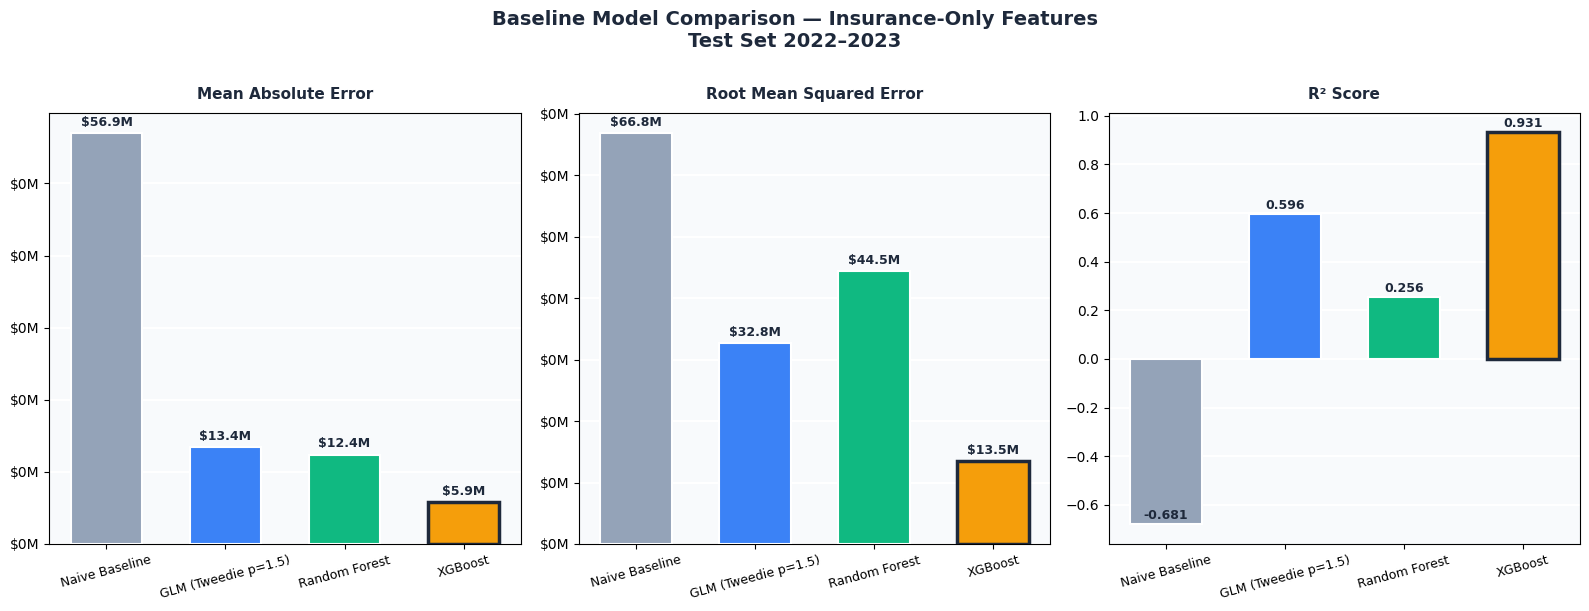

  baseline_model_comparison.png


In [9]:

# ── FIGURE 1: Model Comparison Bar Chart ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.patch.set_facecolor("white")
fig.suptitle("Baseline Model Comparison — Insurance-Only Features\n"
             "Test Set 2022–2023",
             fontsize=14, fontweight="bold", color="#1E293B", y=1.01)

metrics_plot = [
    ("MAE",  "Mean Absolute Error",  "MAE_M"),
    ("RMSE", "Root Mean Squared Error", "RMSE_M"),
    ("R²",   "R² Score",             "R2"),
]

for ax, (key, label, col) in zip(axes, metrics_plot):
    vals   = results[col].values
    models = results["Model"].str.replace(" (Gamma + Log link)", "",
                                          regex=False).values
    bars = ax.bar(models, vals, color=M_COLORS,
                  edgecolor="white", linewidth=1.5,
                  width=0.6, zorder=3)
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="y", color="white", linewidth=1.5, zorder=2)
    ax.set_title(label, fontsize=11, fontweight="bold",
                 color="#1E293B", pad=10)
    ax.tick_params(axis="x", rotation=15, labelsize=9)

    # Value labels
    for bar, val in zip(bars, vals):
        label_txt = (f"${val:.1f}M" if key in ("MAE","RMSE")
                     else f"{val:.3f}")
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(vals)*0.01,
                label_txt, ha="center", va="bottom",
                fontsize=9, fontweight="bold", color="#1E293B")

    if key in ("MAE", "RMSE"):
        ax.yaxis.set_major_formatter(FuncFormatter(fmt_millions))

    # Highlight best
    best_idx = int(np.argmin(vals) if key != "R²"
                   else np.argmax(vals))
    bars[best_idx].set_edgecolor("#1E293B")
    bars[best_idx].set_linewidth(2.5)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/baseline_model_comparison.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  baseline_model_comparison.png")

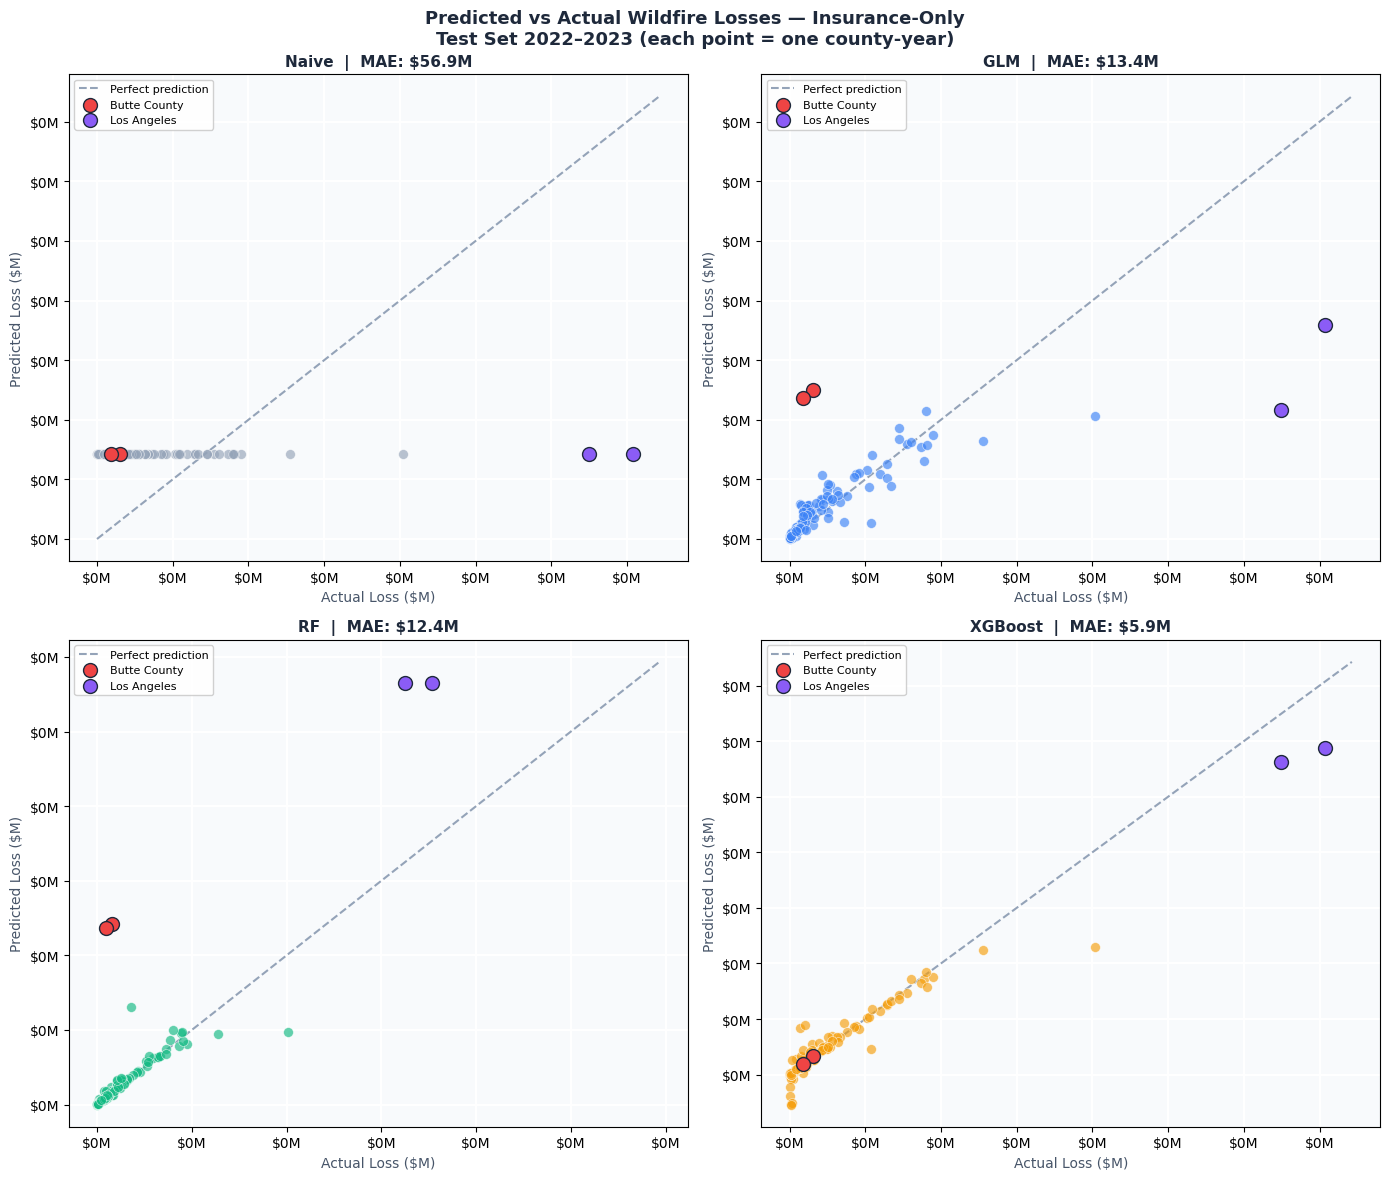

  baseline_predicted_vs_actual.png


In [10]:
# ── FIGURE 2: Predicted vs Actual (4 panels) ─────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.patch.set_facecolor("white")
fig.suptitle("Predicted vs Actual Wildfire Losses — Insurance-Only\n"
             "Test Set 2022–2023 (each point = one county-year)",
             fontsize=13, fontweight="bold", color="#1E293B")

for ax, pred_col, name, color in zip(
        axes.flat, MODEL_COLS, MODEL_NAMES, M_COLORS):

    actual = test[TARGET].values / 1e6
    pred   = test[pred_col].values / 1e6
    mae_m  = mean_absolute_error(test[TARGET], test[pred_col]) / 1e6

    ax.scatter(actual, pred, color=color, alpha=0.65,
               s=50, edgecolors="white", linewidth=0.5, zorder=3)

    # Perfect prediction line
    lim = max(actual.max(), pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], "--", color="#94A3B8",
            linewidth=1.5, zorder=2, label="Perfect prediction")

    # Highlight Butte 2018
    butte = test[(test["County"] == "Butte") &
                 (test["Cal_Year"].isin([22, 23]))]
    if len(butte):
        ax.scatter(butte[TARGET].values/1e6,
                   butte[pred_col].values/1e6,
                   color="#EF4444", s=100, zorder=5,
                   edgecolors="#1E293B", linewidth=1,
                   label="Butte County")

    # LA county
    la = test[(test["County"] == "Los Angeles") &
              (test["Cal_Year"].isin([22, 23]))]
    if len(la):
        ax.scatter(la[TARGET].values/1e6,
                   la[pred_col].values/1e6,
                   color="#8B5CF6", s=100, zorder=5,
                   edgecolors="#1E293B", linewidth=1,
                   label="Los Angeles")

    ax.set_facecolor("#F8FAFC")
    ax.grid(color="white", linewidth=1.5, zorder=1)
    ax.set_xlabel("Actual Loss ($M)", fontsize=10, color="#475569")
    ax.set_ylabel("Predicted Loss ($M)", fontsize=10, color="#475569")
    ax.set_title(f"{name}  |  MAE: ${mae_m:.1f}M",
                 fontsize=11, fontweight="bold", color="#1E293B")
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_millions))
    ax.yaxis.set_major_formatter(FuncFormatter(fmt_millions))
    ax.legend(fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/baseline_predicted_vs_actual.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  baseline_predicted_vs_actual.png")

  Shared x-axis: $-308M to $262M


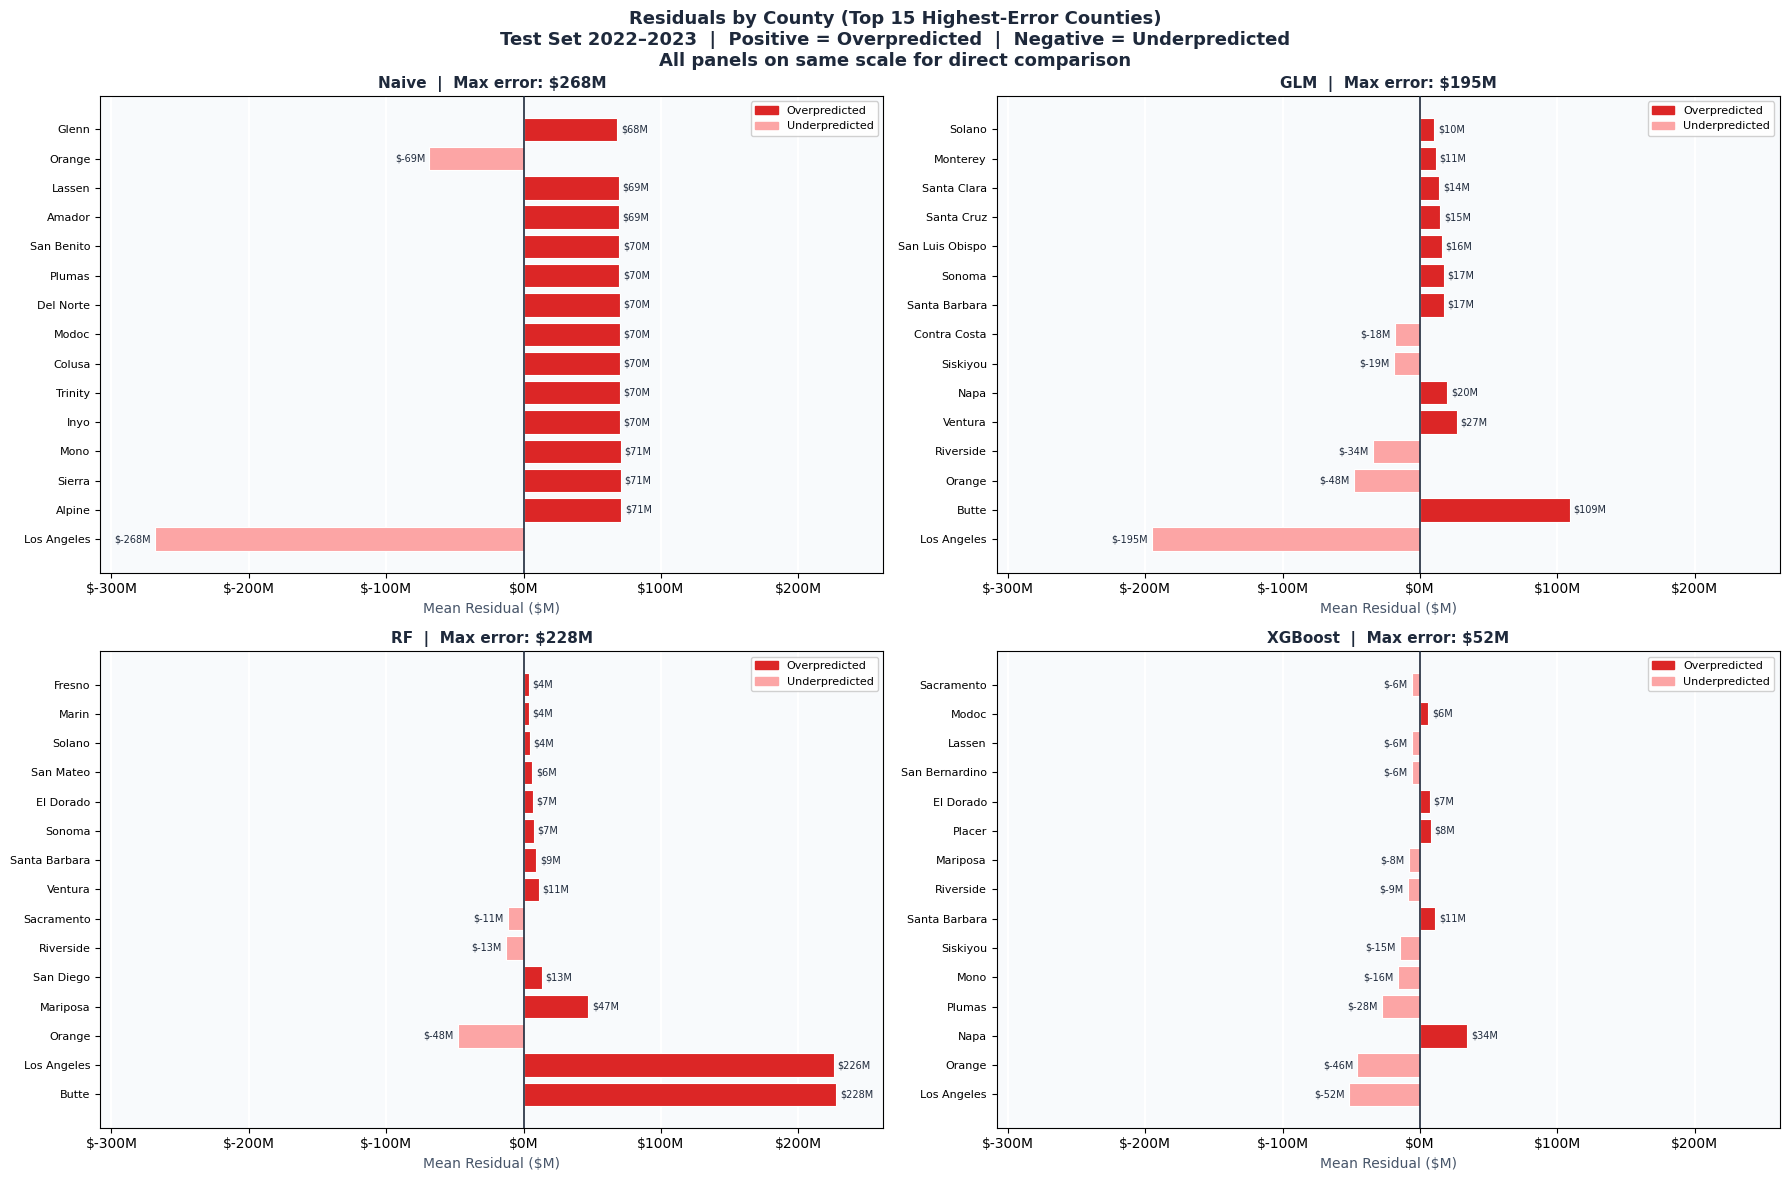

  baseline_residuals_by_county.png


In [11]:
# ── FIGURE 3: Residuals by County (Top 15 error counties) ────
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor("white")
fig.suptitle("Residuals by County (Top 15 Highest-Error Counties)\n"
             "Test Set 2022–2023  |  Positive = Overpredicted  "
             "|  Negative = Underpredicted\n"
             "All panels on same scale for direct comparison",
             fontsize=13, fontweight="bold", color="#1E293B")

# Compute global x-axis range across all models first
all_residuals = []
for pred_col in MODEL_COLS:
    test["residual"] = (test[pred_col] - test[TARGET]) / 1e6
    county_resid = (test.groupby("County")["residual"]
                    .mean().reset_index()
                    .sort_values("residual", key=abs, ascending=False)
                    .head(15))
    all_residuals.extend(county_resid["residual"].tolist())

x_min = min(all_residuals) * 1.15
x_max = max(all_residuals) * 1.15
print(f"  Shared x-axis: ${x_min:.0f}M to ${x_max:.0f}M")

for ax, pred_col, name, color in zip(
        axes.flat, MODEL_COLS, MODEL_NAMES, M_COLORS):

    test["residual"] = (test[pred_col] - test[TARGET]) / 1e6
    county_resid = (test.groupby("County")["residual"]
                    .mean().reset_index()
                    .sort_values("residual", key=abs, ascending=False)
                    .head(15))

    # Single color scheme across all panels — red/orange shades
    # Dark red = overpredicted, light orange = underpredicted
    bar_colors = ["#DC2626" if v >= 0 else "#FCA5A5"
                  for v in county_resid["residual"]]
    bars = ax.barh(county_resid["County"],
                   county_resid["residual"],
                   color=bar_colors, edgecolor="white",
                   linewidth=0.8, zorder=3)
    ax.axvline(0, color="#1E293B", linewidth=1.2, zorder=4)
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="x", color="white", linewidth=1.5, zorder=2)
    ax.set_xlabel("Mean Residual ($M)", fontsize=10, color="#475569")
    ax.set_title(f"{name}  |  Max error: "
                 f"${county_resid['residual'].abs().max():.0f}M",
                 fontsize=11, fontweight="bold", color="#1E293B")

    # Same scale for all panels
    ax.set_xlim(x_min, x_max)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"${x:.0f}M"))
    ax.tick_params(axis="y", labelsize=8)

    # Value labels on bars
    for bar, val in zip(bars, county_resid["residual"]):
        xpos = bar.get_width() + (x_max * 0.01
               if val >= 0 else x_min * 0.01)
        ax.text(xpos, bar.get_y() + bar.get_height()/2,
                f"${val:.0f}M", va="center",
                ha="left" if val >= 0 else "right",
                fontsize=7, color="#1E293B")

    over  = mpatches.Patch(color="#DC2626", label="Overpredicted")
    under = mpatches.Patch(color="#FCA5A5", label="Underpredicted")
    ax.legend(handles=[over, under], fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/baseline_residuals_by_county.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  baseline_residuals_by_county.png")

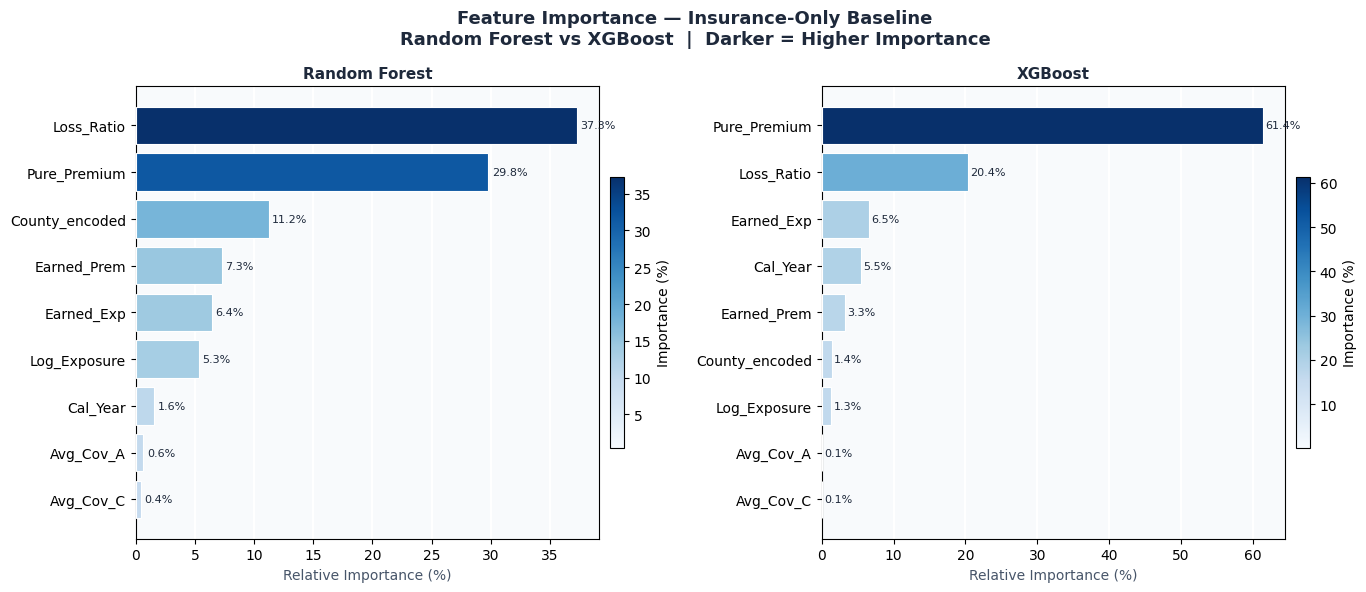

  ✅ baseline_feature_importance.png


In [12]:
# ── FIGURE 4: Feature Importance Comparison ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor("white")
fig.suptitle("Feature Importance — Insurance-Only Baseline\n"
             "Random Forest vs XGBoost  |  Darker = Higher Importance",
             fontsize=13, fontweight="bold", color="#1E293B")

# Same colormap for both panels — Blues scaled by importance
import matplotlib.cm as cm

for ax, importance_df, name in zip(
        axes,
        [rf_importance, xgb_importance],
        ["Random Forest", "XGBoost"]):

    # Normalize to 0-100%
    imp = importance_df.copy()
    imp["Importance"] = (imp["Importance"] /
                          imp["Importance"].sum() * 100)
    imp = imp.sort_values("Importance")

    # Scale colors: higher importance → darker blue
    norm   = plt.Normalize(imp["Importance"].min(),
                           imp["Importance"].max())
    colors = cm.Blues(norm(imp["Importance"]) * 0.75 + 0.25)

    bars = ax.barh(imp["Feature"], imp["Importance"],
                   color=colors, edgecolor="white",
                   linewidth=0.8, zorder=3)
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="x", color="white", linewidth=1.5, zorder=2)
    ax.set_xlabel("Relative Importance (%)",
                  fontsize=10, color="#475569")
    ax.set_title(name, fontsize=11,
                 fontweight="bold", color="#1E293B")

    for bar, val in zip(bars, imp["Importance"]):
        ax.text(bar.get_width() + 0.3,
                bar.get_y() + bar.get_height()/2,
                f"{val:.1f}%", va="center",
                fontsize=8, color="#1E293B")

    # Colorbar to show importance scale
    sm = plt.cm.ScalarMappable(cmap="Blues",
                                norm=plt.Normalize(
                                    imp["Importance"].min(),
                                    imp["Importance"].max()))
    sm.set_array([])
    plt.colorbar(sm, ax=ax, label="Importance (%)",
                 shrink=0.6, pad=0.02)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/baseline_feature_importance.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  ✅ baseline_feature_importance.png")


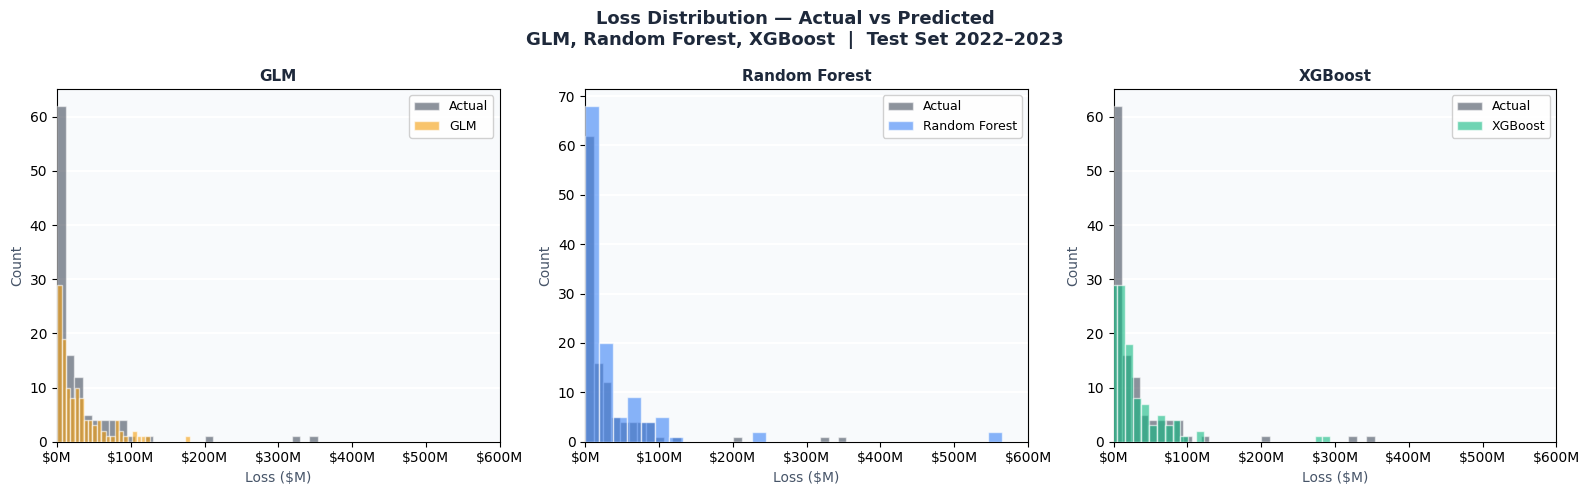

  ✅ baseline_loss_distribution.png


In [13]:
# ── FIGURE 5: Loss Distribution — Actual vs Predicted ────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor("white")
fig.suptitle("Loss Distribution — Actual vs Predicted\n"
             "GLM, Random Forest, XGBoost  |  Test Set 2022–2023",
             fontsize=13, fontweight="bold", color="#1E293B")

for ax, pred_col, name, color in zip(
        axes,
        ["glm_pred", "rf_pred", "xgb_pred"],
        ["GLM", "Random Forest", "XGBoost"],
        ["#F59E0B", "#3B82F6", "#10B981"]):  # yellow, blue, green

    actual_m = test[TARGET].values / 1e6
    pred_m   = test[pred_col].values / 1e6

    ax.hist(actual_m, bins=30, alpha=0.5, color=COLORS["Actual"],
            label="Actual", edgecolor="white", zorder=3)
    ax.hist(pred_m,   bins=30, alpha=0.6, color=color,
            label=name,   edgecolor="white", zorder=3)

    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="y", color="white", linewidth=1.5, zorder=2)
    ax.set_xlabel("Loss ($M)", fontsize=10, color="#475569")
    ax.set_ylabel("Count",     fontsize=10, color="#475569")
    ax.set_title(name, fontsize=11,
                 fontweight="bold", color="#1E293B")
    # Values already in $M — format directly, no division
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"${x:.0f}M"))
    ax.set_xlim(0, 600)   # shared scale across all 3 panels
    ax.legend(fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/baseline_loss_distribution.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  ✅ baseline_loss_distribution.png")

In [16]:
# ── FINAL SUMMARY ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("BASELINE MODELING COMPLETE")
print("=" * 65)
print(f"\n{'Model':<30} {'MAE':>12} {'RMSE':>12} {'R²':>8}")
print("-" * 64)
for _, r in results.iterrows():
    name = r["Model"].replace(" (Tweedie p=1.5 + Log link)", "")
    best_mae = results["MAE"].min()
    marker = " ★" if r["MAE"] == best_mae else ""
    print(f"  {name:<28} ${r['MAE']/1e6:>8.1f}M  "
          f"${r['RMSE']/1e6:>8.1f}M  {r['R2']:>7.4f}{marker}")

print(f"\nPlots saved to: {PLOT_DIR}")
print("  1. baseline_model_comparison.png    — MAE/RMSE/R² bar charts")
print("  2. baseline_predicted_vs_actual.png — scatter plots")
print("  3. baseline_residuals_by_county.png — county-level errors")
print("  4. baseline_feature_importance.png  — RF vs XGB importance")
print("  5. baseline_loss_distribution.png   — actual vs predicted dist")

# Save predictions for later comparison with enhanced models
test[["County", "Cal_Year", "Year_4digit", TARGET,
      "naive_pred", "glm_pred", "rf_pred", "xgb_pred"]].to_csv(
    f"{OUTPUT_DIR}/baseline_predictions.csv", index=False)
print(f"\n  ✅ baseline_predictions.csv saved for model comparison")

# Save trained XGBoost model for SHAP analysis
xgb_model.save_model(f"{OUTPUT_DIR}/xgb_baseline_model.json")
print(f"  ✅ xgb_baseline_model.json saved")


BASELINE MODELING COMPLETE

Model                                   MAE         RMSE       R²
----------------------------------------------------------------
  Naive Baseline               $    56.9M  $    66.8M  -0.6808
  GLM (Tweedie p=1.5)          $    13.4M  $    32.8M   0.5958
  Random Forest                $    12.4M  $    44.5M   0.2556
  XGBoost                      $     5.9M  $    13.5M   0.9314 ★

Plots saved to: <PROJECT_ROOT>/Data/../Plots
  1. baseline_model_comparison.png    — MAE/RMSE/R² bar charts
  2. baseline_predicted_vs_actual.png — scatter plots
  3. baseline_residuals_by_county.png — county-level errors
  4. baseline_feature_importance.png  — RF vs XGB importance
  5. baseline_loss_distribution.png   — actual vs predicted dist

  ✅ baseline_predictions.csv saved for model comparison
  ✅ xgb_baseline_model.json saved


In [15]:
#Top 2 to keep:
#1. Model Comparison Bar Chart — your headline result. Anyone reading your report will immediately see XGBoost dominates. Essential for RQ2 (do ML models beat GLM?).
#2. Predicted vs Actual Scatter — shows the model isn't just winning on average, it tracks individual county-year losses well. Butte and LA highlighted tell the story of where even the best model struggles.
#Drop or move to appendix:

#Plot 5 (Loss Distribution) — redundant, keep in appendix if needed
#Plot 3 (Residuals) — useful for your case study section but not a top-level result
#Plot 4 (Feature Importance) — save for the enhanced model SHAP analysis which tells a richer story